# $V_{\rm rms}$ map of an slsim deflector

`DeflectorKinematics.vrms_map` predicts the line-of-sight second moment
$V_{\rm rms} = \sqrt{\langle v_{\rm los}^2 \rangle}$ of an slsim `Deflector` with the axisymmetric
Jeans Anisotropic Modelling (JAM) of `JamPy`, using the deflector light as the tracer and its total
(lensing) mass as the potential.

Requirements: slsim with `DeflectorKinematics`, `jampy` and `mgefit`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.cosmology import FlatLambdaCDM

from lenstronomy.Cosmo.lens_cosmo import LensCosmo

from slsim.Deflectors.deflector import Deflector
from slsim.Deflectors.deflector_kinematics import DeflectorKinematics

## Deflector

`DeflectorKinematics` takes a deflector with light, an astropy cosmology and source redshift.

However, source redshift is generally arbitrary, unless deflector mass normalization is specified with theta_E. If your deflector's mass normalization is specified with physical quantities (e.g., SIS velocity dispersion \[km/s\]), then you can test by changing source redshift and find that predicted Vrms map is not affected by the input source redshift.

In [2]:
deflector_dict = {
    "z": 0.481053,
    "center_x": 0.000000,
    "center_y": 0.000000,
    "kwargs_light": {
        "extended_source_type": "single_sersic",
        "mag_VIS": 21.220085,
        "mag_Y": 20.622005,
        "mag_H": 20.188108,
        "mag_J": 20.400835,
        "mag_F062": 21.489258,
        "mag_F087": 20.891912,
        "mag_F106": 20.646522,
        "mag_F129": 20.466606,
        "mag_F158": 20.256223,
        "mag_F184": 20.164253,
        "mag_F146": 20.387742,
        "mag_F213": 20.096115,
        "mag_g": 22.380176,
        "mag_r": 21.483298,
        "mag_i": 21.097706,
        "mag_z": 20.920315,
        "mag_y": 20.653906,
        "mag_F475X": 22.230124,
        "mag_F606W": 21.665433,
        "mag_F814W": 21.018238,
        "mag_F160W": 20.262605,
        "mag_F115W": 20.603753,
        "mag_F150W": 20.291520,
        "mag_F200W": 20.133592,
        "mag_F277W": 19.964010,
        "mag_F356W": 20.375679,
        "mag_F444W": 20.694385,
        "mag_F425": 22.623346,
        "mag_F625": 21.527308,
        "mag_F875": 20.873067,
        "mag_Jbb": 20.449227,
        "mag_Hbb": 20.233561,
        "mag_Kp": 20.104367,
        "mag_MICJ": 20.514231,
        "mag_MICH": 20.235206,
        "mag_MICKs": 20.089625,
        "angular_size": 0.934183,
        "physical_size": 5.584717,
        "e1": -0.156653,
        "e2": -0.131999,
        "n_sersic": 1,
        "vel_disp": 316.898046,
        "stellar_mass": 2.89782e10,
    },
    "kwargs_mass": {
        "mass_type": "EPL",
        "e1": -0.371517,
        "e2": -0.134980,
        "gamma_pl": 2,
        "vel_disp": 316.898046,
        "sis_convention": False,
        "theta_E": None,  # setting theta_E to None will use vel_disp to compute theta_E
    },
}

deflector_class = Deflector(**deflector_dict)

z_source = 0.788751
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

kinematics_class = DeflectorKinematics(
    deflector_class=deflector_class,
    astropy_cosmo=cosmo,
    z_source=5,  # input z_source is generally arbitrary unless deflector mass is specified with theta_E
)

/var/folders/r1/1npt_dcs5vb2lf_h7h64vh840000gn/T/ipykernel_30180/3686024979.py:67: UserWarning: Axis ratios: q_light=0.660, q_mass=0.433. Position angles of light and mass differ by 10.1 deg. JAM assumes a common symmetry axis; the difference is ignored.
  kinematics_class = DeflectorKinematics(


## $V_{\rm rms}$ map

`vrms_map` evaluates $V_{\rm rms}$ on a square map of bins centred on the deflector. Parameters:

- `map_half_size`, `grid_size`: half size of the map and size of each bin [arcsec],
- `pix_size`: pixel size of the kinematic data [arcsec], used in the PSF convolution,
- `inc`: inclination [deg], within `(kinematics_class.inclination_min(), 90]`; if `None`, drawn at
  random from isotropic orientations and printed,
- `beta`: stellar orbit anisotropy, constant or one value per Gaussian of the light MGE,
- `sigma_psf`, `norm_psf`: dispersions [arcsec] and flux fractions of the circular Gaussians of the
  PSF of the kinematic data,
- `kwargs_mge_light`, `kwargs_mge_mass`: keyword arguments of `light_mge` and `mass_mge` (e.g.
  `ngauss`, the number of Gaussians of the multi-Gaussian expansions); if `None`, their defaults,
- `dimensionless`: if `True`, `model` is the dimensionless kinematics
  $J = V_{\rm rms}^2 D_{\rm ds} / (D_{\rm s} c^2)$ instead of $V_{\rm rms}$ [km/s], with the distances
  from the source redshift and cosmology of the class,
- `frame`: frame of the returned bins; `"galaxy"` (default) has $x$ along the projected major axis
  of the light, `"sky"` has the axes of the lenstronomy (image) coordinates, i.e. the galaxy frame
  rotated counterclockwise by the light position angle,
- other keyword arguments are passed to `jampy`'s `jam_axi_proj` (e.g. `nrad`, `nang`, `step`).

It returns a dictionary with
- `xbin`, `ybin`: bin centres [arcsec] (1d arrays) in the chosen frame, relative to the deflector
  centre,
- `model`: $V_{\rm rms}$ [km/s] of each bin, or $J$ if `dimensionless=True`,
- `flux`: PSF-convolved model surface brightness of each bin (arbitrary units),
- `shape`: 2d shape of the map, to reshape the 1d arrays,
- `dimensionless`: whether `model` is $J$,
- `dds`, `ds`: angular diameter distances deflector–source and observer–source [Mpc], to convert
  `model` with `vrms_to_J` or `J_to_vrms`,
- `frame`: frame of the bins,
- `pa_light_sky`: position angle of the light in the sky frame [rad], counterclockwise from $+x$
  (lenstronomy convention); `util.rotate(xbin, ybin, -pa_light_sky)` (with `util` from
  `lenstronomy.Util`) rotates galaxy-frame bins into the sky frame, and
  `util.rotate(xbin, ybin, pa_light_sky)` sky-frame bins into the galaxy frame.

inclination: 72.89 deg
output of kinematics_class.vrms_map is dictionary with keys: dict_keys(['xbin', 'ybin', 'model', 'flux', 'shape', 'dimensionless', 'dds', 'ds', 'frame', 'pa_light_sky'])


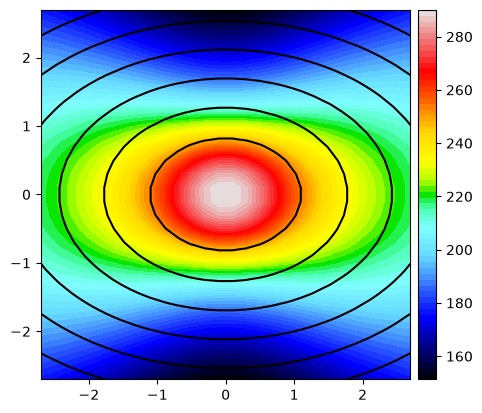

In [3]:
map_half_size = 3 * deflector_class.angular_size_light  # arcsec
pix_size = 0.2  # arcsec, used for PSF convolution
grid_size = pix_size  # arcsec, intentionally same as pix_size; you can set it to a different value if you want to supersample the vrms model
psf_fwhm = 0.8  # arcsec

inc = DeflectorKinematics.draw_inclination(
    kinematics_class.inclination_min(), rng=np.random.default_rng(123)
)
print(f"inclination: {inc:.2f} deg")

vrms_map = kinematics_class.vrms_map(
    map_half_size=map_half_size,
    grid_size=grid_size,
    pix_size=pix_size,
    inc=inc,
    beta=0.0,
    sigma_psf=psf_fwhm / (2 * np.sqrt(2 * np.log(2))),
    norm_psf=1.0,
    dimensionless=False,  # if True, the returned model will be dimensionless J (scales with Vrms**2); reference: eq. 4.11 of https://arxiv.org/pdf/1511.03662
    frame="galaxy",  # if set to "sky", the vrms map will be rotated to the sky frame using the deflector's light position angle.
)

print("output of kinematics_class.vrms_map is dictionary with keys:", vrms_map.keys())

# utility function to plot the vrms map, you can install using pip install plotbin
# alternative is to use plt.imshow(vrms_map["model"], extent=[...], origin="lower") to plot the vrms map
from plotbin.plot_velfield import plot_velfield

plt.figure()
plot_velfield(
    vrms_map["xbin"],
    vrms_map["ybin"],
    vrms_map["model"],
    flux=vrms_map["flux"],
    nodots=True,
    colorbar=True,
)
plt.show()

There is a utility function in DeflectorKinematics class that convert Vrms to dimensionless, cosmo-independent J, defined as
$$
J = \frac{1}{c^2} \frac{D_{\rm ds}}{D_{\rm s}} V_{\rm rms}^2,
$$

where $c$ is the speed of light, $D_{\rm s}$ the angular diameter distance to the source and
$D_{\rm ds}$ the one between the deflector and the source. `vrms_to_J` takes $V_{\rm rms}$ in km/s;
`J_to_vrms` is its inverse.


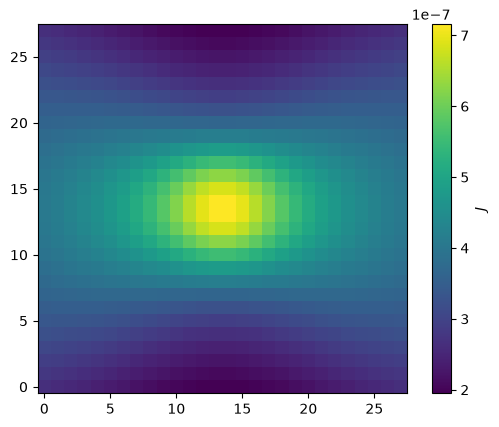

In [4]:
j_map = kinematics_class.vrms_to_J(
    vrms=vrms_map["model"], dds=vrms_map["dds"], ds=vrms_map["ds"]
)

plt.imshow(j_map.reshape(vrms_map["shape"]), origin="lower", cmap="viridis")
plt.colorbar(label=r"$J$")
plt.show()

You can also calculate the aperture-integrated model:

In [5]:
vrms_aperture = kinematics_class.vrms_aperture(
    vrms_map_dict=vrms_map,
    aperture_type="circular",
    kwargs_aperture={"radius": 1.0},  # arcsec
)

print(f"vrms_aperture: {vrms_aperture:.2f} km/s")

vrms_aperture: 269.08 km/s


## J map

Input `dimensionless = True` for `DeflectorKinematics.vrms_map` returns the dimensionless J (reference: $H$ in eq. 4.11 of [https://arxiv.org/pdf/1511.03662]), which is cosmology-independent and scales with $V^2_{\rm rms}$.  

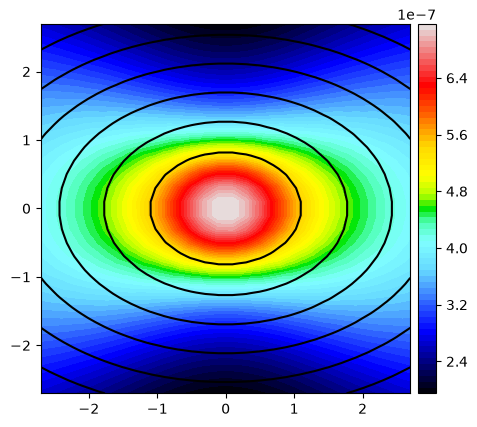

In [6]:
J_map = kinematics_class.vrms_map(
    map_half_size=map_half_size,
    grid_size=grid_size,
    pix_size=pix_size,
    inc=inc,
    beta=0.0,
    sigma_psf=psf_fwhm / (2 * np.sqrt(2 * np.log(2))),
    norm_psf=1.0,
    dimensionless=1,  # if True, the returned model will be dimensionless J (scales with Vrms**2); reference: eq. 4.11 of https://arxiv.org/pdf/1511.03662
    frame="galaxy",  # if set to "sky", the vrms map will be rotated to the sky frame using the deflector's light position angle.
)

plt.figure()
plot_velfield(
    J_map["xbin"],
    J_map["ybin"],
    J_map["model"],
    flux=J_map["flux"],
    nodots=True,
    colorbar=True,
)
plt.show()

`J` summed inside an aperture:

In [7]:
J_aperture = kinematics_class.vrms_aperture(
    vrms_map_dict=J_map,
    aperture_type="circular",
    kwargs_aperture={"radius": 1.0},  # arcsec
)

print(f"J_aperture: {J_aperture}")

J_aperture: 6.163812850607394e-07


Convert back to physical units:

In [8]:
vrms_aperture = kinematics_class.J_to_vrms(
    J=J_aperture, dds=J_map["dds"], ds=J_map["ds"]
)

print(f"vrms_aperture: {vrms_aperture:.2f} km/s")

vrms_aperture: 269.08 km/s
